<a href="https://colab.research.google.com/github/div-200/Skin-Cancer-Classification-Using-Transfer-Learning./blob/main/Copy_of_Skin_cancer_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q kaggle tensorflow pandas numpy matplotlib seaborn scikit-learn

In [ ]:
!pip install -q kaggle

In [ ]:
import os

os.environ["KAGGLE_API_TOKEN"] = "PASTE_YOUR_NEW_TOKEN_HERE"

print("Token added successfully!")

Token added successfully!


In [ ]:
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p /content/data

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [01:01<00:00, 90.4MB/s]



In [ ]:
import os

print(os.listdir("/content/data"))

['skin-cancer-mnist-ham10000.zip']


In [ ]:
import zipfile
import glob
import os

os.makedirs("/content/data/HAM10000", exist_ok=True)

for file in glob.glob("/content/data/*.zip"):
    with zipfile.ZipFile(file, "r") as zip_ref:
        zip_ref.extractall("/content/data/HAM10000")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import os

for root, dirs, files in os.walk("/content/data/HAM10000"):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("Sample files:", files[:5])

Folder: /content/data/HAM10000
Number of files: 5
Sample files: ['hmnist_28_28_L.csv', 'hmnist_8_8_RGB.csv', 'hmnist_28_28_RGB.csv', 'HAM10000_metadata.csv', 'hmnist_8_8_L.csv']
Folder: /content/data/HAM10000/HAM10000_images_part_1
Number of files: 5000
Sample files: ['ISIC_0029204.jpg', 'ISIC_0025841.jpg', 'ISIC_0025665.jpg', 'ISIC_0029232.jpg', 'ISIC_0028263.jpg']
Folder: /content/data/HAM10000/HAM10000_images_part_2
Number of files: 5015
Sample files: ['ISIC_0033045.jpg', 'ISIC_0032699.jpg', 'ISIC_0033273.jpg', 'ISIC_0033243.jpg', 'ISIC_0030964.jpg']
Folder: /content/data/HAM10000/ham10000_images_part_1
Number of files: 5000
Sample files: ['ISIC_0029204.jpg', 'ISIC_0025841.jpg', 'ISIC_0025665.jpg', 'ISIC_0029232.jpg', 'ISIC_0028263.jpg']
Folder: /content/data/HAM10000/ham10000_images_part_2
Number of files: 5015
Sample files: ['ISIC_0033045.jpg', 'ISIC_0032699.jpg', 'ISIC_0033273.jpg', 'ISIC_0033243.jpg', 'ISIC_0030964.jpg']


In [ ]:
import glob

csv_files = glob.glob(
    "/content/data/HAM10000/**/HAM10000_metadata.csv",
    recursive=True
)

print(csv_files)

['/content/data/HAM10000/HAM10000_metadata.csv']


In [ ]:
import pandas as pd

metadata = pd.read_csv(csv_files[0])

print(metadata.head())
print("Total images:", len(metadata))
print("Classes:", metadata["dx"].unique())

     lesion_id      image_id   dx dx_type   age   sex localization
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear
Total images: 10015
Classes: ['bkl' 'nv' 'df' 'mel' 'vasc' 'bcc' 'akiec']


In [ ]:
import glob
import os

image_files = glob.glob(
    "/content/data/HAM10000/**/*.jpg",
    recursive=True
)

print("Total images found:", len(image_files))
print("First 5 images:")

for img in image_files[:5]:
    print(os.path.basename(img))

Total images found: 20030
First 5 images:
ISIC_0029204.jpg
ISIC_0025841.jpg
ISIC_0025665.jpg
ISIC_0029232.jpg
ISIC_0028263.jpg


In [ ]:
import os
from collections import Counter

names = [os.path.basename(img) for img in image_files]

print("Total image files:", len(names))
print("Unique image names:", len(set(names)))

Total image files: 20030
Unique image names: 10015


In [ ]:
print(metadata["dx"].value_counts())

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [ ]:
import os
import glob

image_files = glob.glob(
    "/content/data/HAM10000/**/*.jpg",
    recursive=True
)

image_dict = {}

for path in image_files:
    image_name = os.path.basename(path)
    image_dict[image_name] = path

print("Unique images:", len(image_dict))

Unique images: 10015


In [ ]:
metadata["image_path"] = metadata["image_id"].apply(
    lambda x: image_dict.get(x + ".jpg")
)

print("Total records:", len(metadata))
print("Images matched:", metadata["image_path"].notna().sum())
print("Missing images:", metadata["image_path"].isna().sum())

Total records: 10015
Images matched: 10015
Missing images: 0


In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    metadata,
    test_size=0.2,
    random_state=42,
    stratify=metadata["dx"]
)

print("Training images:", len(train_df))
print("Testing images:", len(test_df))

Training images: 8012
Testing images: 2003


In [ ]:
import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 7

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (224, 224))
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

class_names = sorted(metadata["dx"].unique())
class_to_index = {name: i for i, name in enumerate(class_names)}

train_paths = train_df["image_path"].values
train_labels = train_df["dx"].map(class_to_index).values

test_paths = test_df["image_path"].values
test_labels = test_df["dx"].map(class_to_index).values

train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_ds = train_ds.map(load_image, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.shuffle(1000).batch(32).prefetch(AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_ds = test_ds.map(load_image, num_parallel_calls=AUTOTUNE)
test_ds = test_ds.batch(32).prefetch(AUTOTUNE)

print("Training and testing batches prepared!")
print("Classes:", class_names)

Training and testing batches prepared!
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(7, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,855 (9.24 MB)

 Trainable params: 164,871 (644.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10
)

Epoch 1/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 81s 250ms/step - accuracy: 0.6917 - loss: 0.8888 - val_accuracy: 0.7499 - val_loss: 0.7281
Epoch 2/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 47s 171ms/step - accuracy: 0.7369 - loss: 0.7392 - val_accuracy: 0.7419 - val_loss: 0.7075
Epoch 3/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 45s 164ms/step - accuracy: 0.7524 - loss: 0.6906 - val_accuracy: 0.7599 - val_loss: 0.6701
Epoch 4/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 45s 164ms/step - accuracy: 0.7606 - loss: 0.6605 - val_accuracy: 0.7564 - val_loss: 0.6725
Epoch 5/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 45s 164ms/step - accuracy: 0.7695 - loss: 0.6338 - val_accuracy: 0.7649 - val_loss: 0.6434
Epoch 6/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 43s 155ms/step - accuracy: 0.7792 - loss: 0.6019 - val_accuracy: 0.7733 - val_loss: 0.6334
Epoch 7/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 45s 164ms/step - accuracy: 0.7810 - loss: 0.5909 - val_accuracy: 0.7763 - val_loss: 0.6167
Epoch 8/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 43s 155ms/step - accuracy: 0.7884 - loss: 0

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 169ms/step - accuracy: 0.7863 - loss: 0.6061
Test Loss: 0.60614413022995
Test Accuracy: 78.63 %


In [ ]:
from sklearn.metrics import classification_report
import numpy as np

y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

63/63 ━━━━━━━━━━━━━━━━━━━━ 15s 182ms/step
              precision    recall  f1-score   support

       akiec       0.59      0.26      0.36        65
         bcc       0.55      0.66      0.60       103
         bkl       0.56      0.60      0.58       220
          df       0.67      0.17      0.28        23
         mel       0.56      0.33      0.42       223
          nv       0.87      0.94      0.90      1341
        vasc       0.74      0.61      0.67        28

    accuracy                           0.79      2003
   macro avg       0.65      0.51      0.54      2003
weighted avg       0.77      0.79      0.77      2003



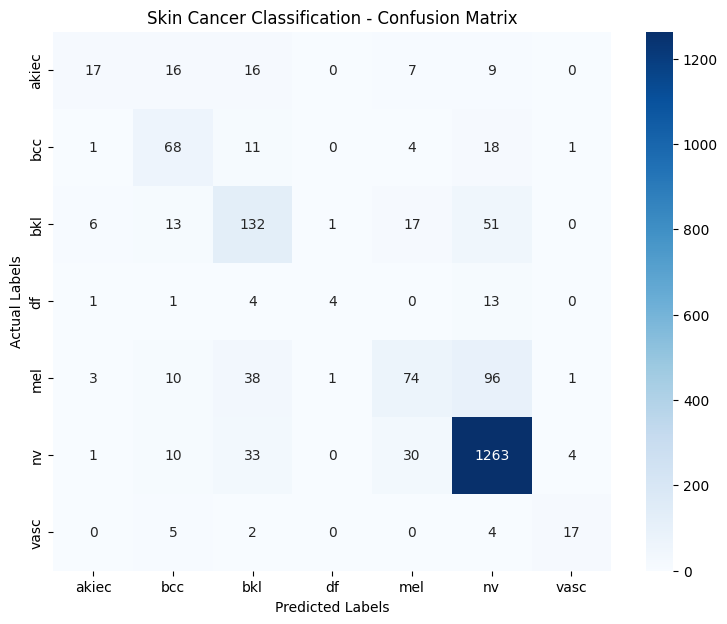

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.title("Skin Cancer Classification - Confusion Matrix")
plt.show()

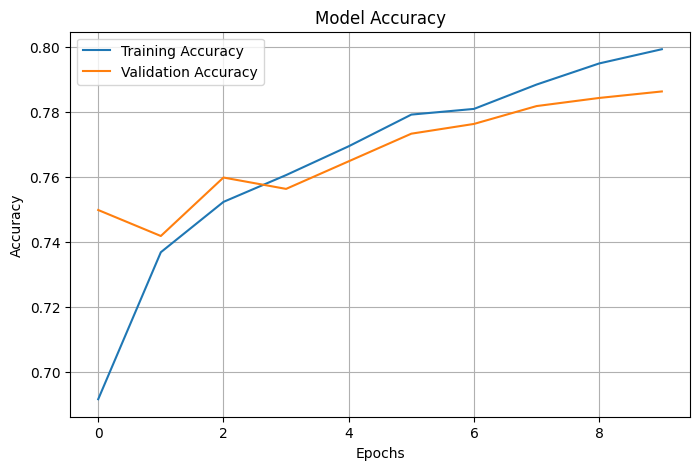

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

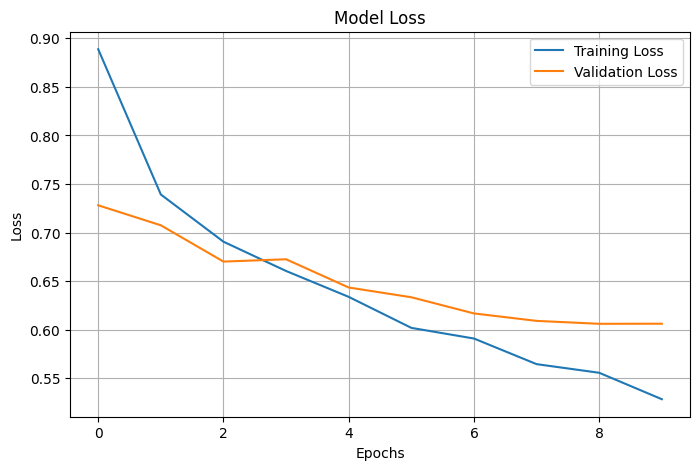

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [ ]:
model.save("/content/skin_cancer_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
!pip install -q gradio

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving skin_cancer_model.keras to skin_cancer_model.keras


In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "/content/skin_cancer_model.keras"
)

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
import gradio as gr
import numpy as np
from PIL import Image

class_names = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

def predict_skin_cancer(image):

    image = image.convert("RGB")
    image = image.resize((224, 224))

    img_array = np.array(image, dtype=np.float32)

    img_array = tf.keras.applications.mobilenet_v2.preprocess_input(
        img_array
    )

    img_array = np.expand_dims(img_array, axis=0)

    predictions = model.predict(img_array)[0]

    results = {
        class_names[i]: float(predictions[i])
        for i in range(len(class_names))
    }

    return results


app = gr.Interface(
    fn=predict_skin_cancer,
    inputs=gr.Image(type="pil", label="Upload Skin Lesion Image"),
    outputs=gr.Label(num_top_classes=3, label="Prediction Results"),
    title="Skin Cancer Classification Using Transfer Learning",
    description="MobileNetV2-based skin lesion image classification."
)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://38ffce315264d06dfe.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
